# Model comparison - 3D vs 2D vs PressureVision

Compares the 3D (`Model/`), 2D (`Model2D/`) and PressureVision models on the test frames they ALL predicted, from the `predictions.csv` files their `evaluate.py` scripts write (one per trained run, e.g. one per seed).

Checks first that every run used the same test sessions (`splits.json` next to each checkpoint) and that the true labels agree, then reports per model (mean ± std over its runs, i.e. seeds):

* overall MAE / RMSE / R² / bias, next to the trivial baseline (always predict the mean training force)
* no-contact frames (true <= contact threshold): MAE, mean predicted force and false-force rate (prediction above the threshold while not touching)
* contact frames: MAE, contact accuracy / precision / recall / F1
* MAE per force bin
* dynamic frames (|dF/dt| above a threshold: press onsets and releases) vs static frames - where temporal context should matter
* MAE per test session
* uncertainty: 95% bootstrap intervals over the test SESSIONS (resampled with replacement) for every model's MAE and every pairwise MAE difference, plus the seed-to-seed spread

The last section optionally measures every model's inference cost (`benchmarkModel.py`, one subprocess per model: parameters, FLOPs, latency, throughput, GPU memory, optionally CPU latency). It needs no predictions: to only benchmark, run the setup cell, the helper cells and that section.

Settings and the run folders per model are in `config.yaml`'s `comparison` block. Writes `<output_dir>/summary.json`, `common_predictions.csv`, the figures (IEEE style, `.pdf` and `.png`) and (benchmark) `benchmark.json`. Run with the `trajPipeline` kernel after evaluating every model.

In [103]:
import glob
import json
import os
import re
import subprocess
import sys
import tempfile

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from IPython.display import Markdown, display

RUN_BENCHMARK = False   # True -> also measure inference time / compute per model (last section)

REPO_ROOT = os.path.abspath("")
while not os.path.isfile(os.path.join(REPO_ROOT, "config.yaml")):   # notebook may be started from comparison/ or the repo root
    if os.path.dirname(REPO_ROOT) == REPO_ROOT:
        raise FileNotFoundError("config.yaml not found above the notebook's working directory")
    REPO_ROOT = os.path.dirname(REPO_ROOT)
CONFIG_PATH = os.path.join(REPO_ROOT, "config.yaml")

with open(CONFIG_PATH) as f:
    config = yaml.safe_load(f)
settings = config["comparison"]
thr = settings["contact_threshold_n"]


def repo_path(path):
    """Returns path resolved against the repo root (absolute paths unchanged)."""
    return path if os.path.isabs(path) else os.path.normpath(os.path.join(REPO_ROOT, path))


# IEEE style (as in plotValidation.ipynb): double column (7.16 in) or single column (3.5 in),
# Times-like serif, 8 pt, grayscale + hatching
plt.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Times New Roman", "Times", "Nimbus Roman", "STIXGeneral", "DejaVu Serif"],
    "mathtext.fontset": "stix",
    "font.size": 8,
    "axes.labelsize": 8,
    "axes.titlesize": 8,
    "xtick.labelsize": 7,
    "ytick.labelsize": 7,
    "legend.fontsize": 7,
    "axes.linewidth": 0.5,
    "xtick.major.width": 0.5,
    "ytick.major.width": 0.5,
    "xtick.direction": "in",
    "ytick.direction": "in",
    "hatch.linewidth": 0.5,
    "lines.linewidth": 1.0,
    "lines.markersize": 3,
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "figure.dpi": 200,
    "savefig.dpi": 600,
    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.02,
})
# Per model (order of config.yaml's comparison.models): bar fill and line style, readable in grayscale
BAR_STYLES = [
    {"facecolor": "0.25", "hatch": ""},
    {"facecolor": "0.65", "hatch": ""},
    {"facecolor": "white", "hatch": "////"},
]
LINE_STYLES = [
    {"color": "0.2", "linestyle": "--"},
    {"color": "0.5", "linestyle": "-."},
    {"color": "0.35", "linestyle": ":"},
]
GRID = {"linewidth": 0.3, "color": "0.85"}

out_dir = repo_path(settings["output_dir"])
os.makedirs(out_dir, exist_ok=True)
print(f"[compare] repo root: {REPO_ROOT}\n[compare] outputs: {out_dir}")

[compare] repo root: /home/wouterdg/ForceEstimationPipeline
[compare] outputs: /home/wouterdg/ForceEstimationPipeline/comparison/results


## Helpers

Finding the runs, checking the shared split, loading the labels.

In [104]:
def find_runs(model_patterns):
    """Input: {model name: [glob patterns of eval_<split> folders]}. Returns
    {model name: [eval folder, ...]} for the folders that contain a
    predictions.csv (models without any run are left out, with a warning).
    """
    runs = {}
    for name, patterns in model_patterns.items():
        found = sorted({os.path.normpath(path) for pattern in patterns for path in glob.glob(repo_path(pattern))
                        if os.path.isfile(os.path.join(path, "predictions.csv"))})
        if found:
            runs[name] = found
        else:
            print(f"[compare] WARNING: no predictions.csv found for {name} ({patterns}) - left out")
    return runs


def check_splits(runs):
    """Every run's checkpoint folder (parent of eval_<split>) holds the
    splits.json it was trained with. Returns the shared split; raises if
    any two runs differ (a comparison over different test sessions is
    meaningless).
    """
    splits_by_run = {}
    for name, folders in runs.items():
        for folder in folders:
            path = os.path.join(os.path.dirname(folder), "splits.json")
            if not os.path.isfile(path):
                raise RuntimeError(f"[compare] {path} missing - cannot check that {name} used the same split")
            with open(path) as f:
                splits_by_run[f"{name}: {folder}"] = {split: sorted(names) for split, names in json.load(f).items()}
    reference_run, reference = next(iter(splits_by_run.items()))
    for run, splits in splits_by_run.items():
        for split in ("train", "val", "test"):
            if splits.get(split) != reference.get(split):
                only_here = sorted(set(splits.get(split, [])) - set(reference.get(split, [])))
                only_there = sorted(set(reference.get(split, [])) - set(splits.get(split, [])))
                raise RuntimeError(f"[compare] {split} split differs between\n  {reference_run}\n  {run}\n"
                                   f"  only in the second: {only_here}\n  only in the first: {only_there}\n"
                                   f"Make sure all projects have the same PROCESSED_OK sessions and split settings, then retrain.")
    return reference


def load_truth(data_root, sessions):
    """Labels from the shared processed data: force_n and time for every
    saved frame, plus the force rate |dF/dt| (N/s) from neighbouring frames
    of the same session. Returns a DataFrame keyed by (session, raw_frame_index).
    """
    frames = []
    for name in sessions:
        df = pd.read_csv(os.path.join(data_root, name, "frames.csv"),
                         usecols=["raw_frame_index", "host_ts_ns", "force_n", "artifact"])
        t_s = df["host_ts_ns"].to_numpy() / 1e9
        df["force_rate_n_per_s"] = np.abs(np.gradient(df["force_n"].to_numpy(), t_s)) if len(df) > 1 else 0.0
        df["session"] = name
        frames.append(df)
    return pd.concat(frames, ignore_index=True)


def mean_train_force(data_root, train_sessions, max_label_force_n):
    """Trivial baseline: mean label over the usable training frames (no
    artifact, label <= max_label_force_n), as in every model's evaluate.py.
    """
    labels = []
    for name in train_sessions:
        df = pd.read_csv(os.path.join(data_root, name, "frames.csv"), usecols=["force_n", "artifact"])
        labels.append(df.loc[(df["artifact"] == 0) & (df["force_n"] <= max_label_force_n), "force_n"].to_numpy())
    return float(np.concatenate(labels).mean())

Metrics per run and the session-level bootstrap.

In [105]:
def frame_masks(common, settings):
    """Boolean masks over the common frames for every reported subset."""
    thr = settings["contact_threshold_n"]
    true_n = common["true_n"].to_numpy()
    dynamic = common["force_rate_n_per_s"].to_numpy() > settings["dynamic_force_rate_n_per_s"]
    masks = {"all": np.ones(len(common), dtype=bool), "no_contact": true_n <= thr, "contact": true_n > thr,
             "dynamic": dynamic, "static": ~dynamic}
    edges = settings["force_bins_n"]
    for low, high in zip(edges[:-1], edges[1:]):
        masks[f"bin_{low:g}-{high:g}N"] = (true_n > low) & (true_n <= high)
    return masks


def run_metrics(pred_n, true_n, masks, sessions, thr):
    """All scalar metrics of one run on the common frames."""
    error = pred_n - true_n
    abs_error = np.abs(error)
    ss_tot = np.sum((true_n - true_n.mean()) ** 2)
    pred_contact, true_contact = pred_n > thr, true_n > thr
    tp = np.sum(pred_contact & true_contact)
    precision = tp / max(pred_contact.sum(), 1)
    recall = tp / max(true_contact.sum(), 1)
    metrics = {
        "mae_n": abs_error.mean(),
        "rmse_n": np.sqrt(np.mean(error ** 2)),
        "r2": 1.0 - np.sum(error ** 2) / ss_tot if ss_tot > 0 else np.nan,
        "bias_n": error.mean(),
        "contact_acc": np.mean(pred_contact == true_contact),
        "contact_precision": precision,
        "contact_recall": recall,
        "contact_f1": 2 * precision * recall / max(precision + recall, 1e-12),
        "no_contact_mean_pred_n": pred_n[masks["no_contact"]].mean() if masks["no_contact"].any() else np.nan,
        "no_contact_false_force_rate": pred_contact[masks["no_contact"]].mean() if masks["no_contact"].any() else np.nan,
    }
    for subset, mask in masks.items():
        if subset != "all":
            metrics[f"mae_{subset}_n"] = abs_error[mask].mean() if mask.any() else np.nan
    for session in np.unique(sessions):
        metrics[f"mae_session_{session}_n"] = abs_error[sessions == session].mean()
    return {key: float(value) for key, value in metrics.items()}


def bootstrap(per_run_errors, masks, sessions, settings):
    """Session-level bootstrap. per_run_errors: {model: [abs error array per
    run]}. Resamples the test sessions with replacement; a model's MAE in a
    resample is the mean over its runs. Returns {subset: {"models": {model:
    (low, high)}, "differences": {"A - B": (mean, low, high, P(A<B))}}}.
    """
    rng = np.random.default_rng(settings["bootstrap_seed"])
    session_names = np.unique(sessions)
    session_index = np.searchsorted(session_names, sessions)
    draws = rng.integers(0, len(session_names), size=(settings["bootstrap_samples"], len(session_names)))
    weights = np.stack([np.bincount(draw, minlength=len(session_names)) for draw in draws])   # (B, S)
    results = {}
    for subset in ("all", "no_contact", "contact", "dynamic", "static"):
        mask = masks[subset]
        counts = np.bincount(session_index[mask], minlength=len(session_names)).astype(float)
        frame_total = weights @ counts
        valid = frame_total > 0
        model_mae = {}
        for model, errors_per_run in per_run_errors.items():
            run_maes = [(weights @ np.bincount(session_index[mask], weights=errors[mask], minlength=len(session_names)))
                        / np.where(valid, frame_total, 1) for errors in errors_per_run]
            model_mae[model] = np.mean(run_maes, axis=0)[valid]
        names = list(model_mae)
        results[subset] = {
            "models": {m: [float(np.percentile(v, 2.5)), float(np.percentile(v, 97.5))] for m, v in model_mae.items()},
            "differences": {
                f"{a} - {b}": [float(np.mean(model_mae[a] - model_mae[b])),
                               float(np.percentile(model_mae[a] - model_mae[b], 2.5)),
                               float(np.percentile(model_mae[a] - model_mae[b], 97.5)),
                               float(np.mean(model_mae[a] < model_mae[b]))]
                for i, a in enumerate(names) for b in names[i + 1:]
            },
        }
    return results

Report tables (rendered as Markdown in the notebook).

In [106]:
def coverage_markdown(summary):
    lines = [f"**{summary['num_common_frames']} common test frames, {len(summary['test_sessions'])} test sessions**", "",
             "| run | frames predicted | in common set |", "|---|---|---|"]
    lines += [f"| {run} | {n} | {summary['num_common_frames'] / n * 100:.1f}% |" for run, n in summary["frames_per_run"].items()]
    lines += ["", f"Label check (max |true_n - processed force_n| over common frames): "
                  f"{summary['max_label_difference_n']:.4f} N"]
    return "\n".join(lines)


def metrics_markdown(summary):
    models = list(summary["models"])

    def row(label, key, fmt="{:.3f}"):
        cells = []
        for m in models:
            s = summary["models"][m]["mean"].get(key, np.nan)
            sd = summary["models"][m]["std"].get(key, np.nan)
            cells.append(fmt.format(s) + (f" ± {fmt.format(sd)}" if summary["models"][m]["runs"] > 1 else ""))
        return f"| {label} | " + " | ".join(cells) + f" | {fmt.format(summary['baseline'].get(key, np.nan))} |"

    lines = ["| metric | " + " | ".join(f"{m} ({summary['models'][m]['runs']} run(s))" for m in models) + " | trivial baseline |",
             "|---" * (len(models) + 2) + "|"]
    for label, key in [("MAE (N)", "mae_n"), ("RMSE (N)", "rmse_n"), ("R²", "r2"), ("bias (N)", "bias_n"),
                       ("MAE no contact (N)", "mae_no_contact_n"), ("mean prediction, no contact (N)", "no_contact_mean_pred_n"),
                       ("false-force rate, no contact", "no_contact_false_force_rate"),
                       ("MAE contact (N)", "mae_contact_n"), ("contact accuracy", "contact_acc"),
                       ("contact F1", "contact_f1"), ("MAE dynamic (N)", "mae_dynamic_n"), ("MAE static (N)", "mae_static_n")]:
        lines.append(row(label, key))
    for key in summary["force_bins"]:
        lines.append(row(f"MAE {key[4:]} (N)", f"mae_{key}_n"))
    lines += ["", f"Frames: {summary['subset_sizes']}"]
    return "\n".join(lines)


def bootstrap_markdown(summary):
    lines = []
    for subset, result in summary["bootstrap"].items():
        lines.append(f"**{subset}** - MAE: " + ", ".join(f"{m} [{lo:.3f}, {hi:.3f}]" for m, (lo, hi) in result["models"].items()))
        lines.append("")
        lines += ["| difference | mean (N) | 95% interval | P(first < second) |", "|---|---|---|---|"]
        lines += [f"| {pair} | {d:+.3f} | [{lo:+.3f}, {hi:+.3f}] | {p:.2f} |"
                  for pair, (d, lo, hi, p) in result["differences"].items()]
        lines.append("")
    lines += ["An interval that contains 0 means the difference is not resolved by these test sessions. "
              "Compare differences with the seed-to-seed std above as well."]
    return "\n".join(lines)


def session_markdown(summary):
    models = list(summary["models"])
    lines = ["| session | " + " | ".join(models) + " |", "|---" * (len(models) + 1) + "|"]
    for session in summary["test_sessions"]:
        lines.append(f"| {session} | " + " | ".join(
            f"{summary['models'][m]['mean'].get(f'mae_session_{session}_n', np.nan):.3f}" for m in models) + " |")
    return "\n".join(lines)

## Load the runs and check the split

Every run must have been trained on the same train/val/test sessions.

In [107]:
runs = find_runs(settings["models"])
if len(runs) < 2:
    raise RuntimeError("[compare] need predictions from at least two models")
splits = check_splits(runs)
print(f"[compare] all runs share the split; test sessions: {splits['test']}")

predictions, frames_per_run = {}, {}
for model, folders in runs.items():
    for folder in folders:
        df = pd.read_csv(os.path.join(folder, "predictions.csv"), usecols=["session", "raw_frame_index", "true_n", "pred_n"])
        df = df[df["session"].isin(splits["test"])].drop_duplicates(["session", "raw_frame_index"])
        predictions[(model, folder)] = df.set_index(["session", "raw_frame_index"])
        frames_per_run[f"{model}: {os.path.relpath(folder, REPO_ROOT)}"] = len(df)
        print(f"[compare] {model}: {folder} - {len(df)} frames")

[compare] all runs share the split; test sessions: ['session_20261002_140907', 'session_20261002_142646', 'session_20261002_143513', 'session_20261007_113934', 'session_20261007_132021', 'session_20261019_113917', 'session_20261019_122138', 'session_20261019_124311', 'session_20261019_130516']
[compare] 3D: /home/wouterdg/ForceEstimationPipeline/Model/checkpoints/seed_1/eval_test - 30239 frames
[compare] 3D: /home/wouterdg/ForceEstimationPipeline/Model/checkpoints/seed_2/eval_test - 30239 frames
[compare] 3D: /home/wouterdg/ForceEstimationPipeline/Model/checkpoints/seed_3/eval_test - 30239 frames
[compare] 2D: /home/wouterdg/ForceEstimationPipeline/Model2D/checkpoints/seed_1/eval_test - 30239 frames
[compare] 2D: /home/wouterdg/ForceEstimationPipeline/Model2D/checkpoints/seed_2/eval_test - 30239 frames
[compare] 2D: /home/wouterdg/ForceEstimationPipeline/Model2D/checkpoints/seed_3/eval_test - 30239 frames
[compare] PressureVision: /home/wouterdg/ForceEstimationPressureVision/Model/chec

## Common frames

Only the frames every run predicted are compared; their labels are taken from the shared processed data and checked against each model's `true_n`.

In [108]:
common_index = None
for df in predictions.values():
    common_index = df.index if common_index is None else common_index.intersection(df.index)
if common_index is None or len(common_index) == 0:
    raise RuntimeError("[compare] no frames in common - are the predictions from the same processed sessions?")

data_root = repo_path(settings["data_root"])
truth = load_truth(data_root, splits["test"]).set_index(["session", "raw_frame_index"])
missing = len(common_index.difference(truth.index))
if missing:
    print(f"[compare] WARNING: {missing} common frames are not in {data_root} - left out")
common = truth.loc[common_index.intersection(truth.index).sort_values()].reset_index()
common = common.rename(columns={"force_n": "true_n"})
key = pd.MultiIndex.from_frame(common[["session", "raw_frame_index"]])
max_label_difference = max(float(np.max(np.abs(df.loc[key, "true_n"].to_numpy() - common["true_n"].to_numpy())))
                           for df in predictions.values())
if max_label_difference > 0.05:
    print(f"[compare] WARNING: labels differ by up to {max_label_difference:.3f} N between a model and the processed data")
print(f"[compare] {len(common)} common frames")

[compare] 29590 common frames


## Metrics

Per-run metrics, the trivial baseline and the session bootstrap; saved to `summary.json` and `common_predictions.csv`.

In [109]:
masks = frame_masks(common, settings)
true_n = common["true_n"].to_numpy()
sessions = common["session"].to_numpy()
per_run_metrics, per_run_errors = {}, {}
for (model, folder), df in predictions.items():
    pred_n = df.loc[key, "pred_n"].to_numpy()
    per_run_metrics.setdefault(model, []).append(run_metrics(pred_n, true_n, masks, sessions, thr))
    per_run_errors.setdefault(model, []).append(np.abs(pred_n - true_n))
for model in runs:
    common[f"pred_{model}"] = np.mean([predictions[(model, f)].loc[key, "pred_n"].to_numpy() for f in runs[model]], axis=0)

baseline_n = mean_train_force(data_root, splits["train"], settings["max_label_force_n"])
summary = {
    "test_sessions": splits["test"],
    "num_common_frames": int(len(common)),
    "frames_per_run": frames_per_run,
    "max_label_difference_n": max_label_difference,
    "settings": settings,
    "force_bins": [k for k in masks if k.startswith("bin_")],
    "subset_sizes": {k: int(v.sum()) for k, v in masks.items()},
    "baseline": {"mean_train_force_n": baseline_n,
                 **run_metrics(np.full(len(common), baseline_n), true_n, masks, sessions, thr)},
    "models": {model: {"runs": len(metrics_list),
                       "run_folders": runs[model],
                       "mean": pd.DataFrame(metrics_list).mean().to_dict(),
                       "std": pd.DataFrame(metrics_list).std(ddof=1).fillna(0.0).to_dict(),
                       "per_run": metrics_list}
               for model, metrics_list in per_run_metrics.items()},
    "bootstrap": bootstrap(per_run_errors, masks, sessions, settings),
}

common.to_csv(os.path.join(out_dir, "common_predictions.csv"), index=False)
with open(os.path.join(out_dir, "summary.json"), "w") as f:
    json.dump(summary, f, indent=2)
print(f"[compare] summary.json and common_predictions.csv written to {out_dir}")

[compare] summary.json and common_predictions.csv written to /home/wouterdg/ForceEstimationPipeline/comparison/results


### Coverage

In [110]:
display(Markdown(coverage_markdown(summary)))

**29590 common test frames, 9 test sessions**

| run | frames predicted | in common set |
|---|---|---|
| 3D: Model/checkpoints/seed_1/eval_test | 30239 | 97.9% |
| 3D: Model/checkpoints/seed_2/eval_test | 30239 | 97.9% |
| 3D: Model/checkpoints/seed_3/eval_test | 30239 | 97.9% |
| 2D: Model2D/checkpoints/seed_1/eval_test | 30239 | 97.9% |
| 2D: Model2D/checkpoints/seed_2/eval_test | 30239 | 97.9% |
| 2D: Model2D/checkpoints/seed_3/eval_test | 30239 | 97.9% |
| PressureVision: ../ForceEstimationPressureVision/Model/checkpoints/pressurevision_seed_1/eval_test | 30098 | 98.3% |
| PressureVision: ../ForceEstimationPressureVision/Model/checkpoints/pressurevision_seed_2/eval_test | 30098 | 98.3% |
| PressureVision: ../ForceEstimationPressureVision/Model/checkpoints/pressurevision_seed_3/eval_test | 30098 | 98.3% |

Label check (max |true_n - processed force_n| over common frames): 0.0000 N

### Metrics (mean ± std over runs)

In [111]:
display(Markdown(metrics_markdown(summary)))

| metric | 3D (3 run(s)) | 2D (3 run(s)) | PressureVision (3 run(s)) | trivial baseline |
|---|---|---|---|---|
| MAE (N) | 1.883 ± 0.026 | 2.008 ± 0.041 | 1.876 ± 0.027 | 4.463 |
| RMSE (N) | 2.651 ± 0.019 | 2.836 ± 0.027 | 2.595 ± 0.013 | 5.100 |
| R² | 0.723 ± 0.004 | 0.683 ± 0.006 | 0.735 ± 0.003 | -0.024 |
| bias (N) | 0.351 ± 0.118 | 0.536 ± 0.173 | 0.490 ± 0.014 | 0.773 |
| MAE no contact (N) | 0.670 ± 0.098 | 0.884 ± 0.186 | 0.850 ± 0.051 | 7.006 |
| mean prediction, no contact (N) | 0.672 ± 0.105 | 0.899 ± 0.207 | 0.872 ± 0.055 | 7.049 |
| false-force rate, no contact | 0.273 ± 0.056 | 0.388 ± 0.160 | 0.384 ± 0.039 | 1.000 |
| MAE contact (N) | 2.147 ± 0.023 | 2.252 ± 0.024 | 2.099 ± 0.023 | 3.910 |
| contact accuracy | 0.897 ± 0.005 | 0.878 ± 0.008 | 0.882 ± 0.001 | 0.822 |
| contact F1 | 0.937 ± 0.003 | 0.926 ± 0.003 | 0.929 ± 0.001 | 0.902 |
| MAE dynamic (N) | 2.201 ± 0.062 | 2.436 ± 0.118 | 2.185 ± 0.036 | 3.558 |
| MAE static (N) | 1.864 ± 0.031 | 1.982 ± 0.045 | 1.858 ± 0.027 | 4.517 |
| MAE 0.5-2N (N) | 1.594 ± 0.079 | 1.645 ± 0.171 | 1.625 ± 0.035 | 5.761 |
| MAE 2-5N (N) | 2.310 ± 0.108 | 2.499 ± 0.125 | 2.488 ± 0.035 | 3.452 |
| MAE 5-10N (N) | 2.342 ± 0.118 | 2.458 ± 0.049 | 2.182 ± 0.053 | 1.197 |
| MAE 10-15N (N) | 1.772 ± 0.050 | 1.942 ± 0.090 | 1.740 ± 0.071 | 5.440 |
| MAE 15-30N (N) | 3.687 ± 0.317 | 3.040 ± 0.264 | 2.876 ± 0.109 | 9.302 |

Frames: {'all': 29590, 'no_contact': 5281, 'contact': 24309, 'dynamic': 1667, 'static': 27923, 'bin_0.5-2N': 2853, 'bin_2-5N': 6062, 'bin_5-10N': 7206, 'bin_10-15N': 7014, 'bin_15-30N': 1174}

### 95% bootstrap intervals over test sessions

In [112]:
display(Markdown(bootstrap_markdown(summary)))

**all** - MAE: 3D [1.520, 2.357], 2D [1.647, 2.507], PressureVision [1.533, 2.298]

| difference | mean (N) | 95% interval | P(first < second) |
|---|---|---|---|
| 3D - 2D | -0.122 | [-0.215, -0.027] | 0.99 |
| 3D - PressureVision | +0.012 | [-0.074, +0.112] | 0.41 |
| 2D - PressureVision | +0.135 | [+0.032, +0.253] | 0.00 |

**no_contact** - MAE: 3D [0.256, 1.170], 2D [0.484, 1.445], PressureVision [0.461, 1.293]

| difference | mean (N) | 95% interval | P(first < second) |
|---|---|---|---|
| 3D - 2D | -0.216 | [-0.335, -0.080] | 1.00 |
| 3D - PressureVision | -0.176 | [-0.287, -0.077] | 1.00 |
| 2D - PressureVision | +0.039 | [-0.080, +0.186] | 0.31 |

**contact** - MAE: 3D [1.767, 2.654], 2D [1.885, 2.777], PressureVision [1.742, 2.551]

| difference | mean (N) | 95% interval | P(first < second) |
|---|---|---|---|
| 3D - 2D | -0.103 | [-0.210, +0.003] | 0.97 |
| 3D - PressureVision | +0.054 | [-0.057, +0.181] | 0.19 |
| 2D - PressureVision | +0.157 | [+0.031, +0.301] | 0.01 |

**dynamic** - MAE: 3D [1.820, 2.707], 2D [2.073, 2.998], PressureVision [1.868, 2.628]

| difference | mean (N) | 95% interval | P(first < second) |
|---|---|---|---|
| 3D - 2D | -0.232 | [-0.488, +0.075] | 0.94 |
| 3D - PressureVision | +0.020 | [-0.135, +0.219] | 0.44 |
| 2D - PressureVision | +0.252 | [+0.100, +0.419] | 0.00 |

**static** - MAE: 3D [1.499, 2.337], 2D [1.619, 2.482], PressureVision [1.512, 2.280]

| difference | mean (N) | 95% interval | P(first < second) |
|---|---|---|---|
| 3D - 2D | -0.116 | [-0.203, -0.028] | 1.00 |
| 3D - PressureVision | +0.012 | [-0.076, +0.118] | 0.43 |
| 2D - PressureVision | +0.128 | [+0.025, +0.247] | 0.01 |

An interval that contains 0 means the difference is not resolved by these test sessions. Compare differences with the seed-to-seed std above as well.

### MAE per test session (N, mean over runs)

In [113]:
display(Markdown(session_markdown(summary)))

| session | 3D | 2D | PressureVision |
|---|---|---|---|
| session_20261002_140907 | 2.977 | 3.316 | 2.902 |
| session_20261002_142646 | 2.444 | 2.497 | 2.278 |
| session_20261002_143513 | 1.840 | 1.978 | 1.657 |
| session_20261007_113934 | 2.523 | 2.426 | 2.532 |
| session_20261007_132021 | 1.321 | 1.444 | 1.452 |
| session_20261019_113917 | 1.532 | 1.453 | 1.107 |
| session_20261019_122138 | 1.434 | 1.529 | 1.376 |
| session_20261019_124311 | 1.746 | 1.791 | 1.813 |
| session_20261019_130516 | 1.325 | 1.589 | 1.499 |

## Plots

MAE per 2 N force bin from 0 to 18 N (on the common test frames; the tables above use the bins of `force_bins_n`), and the distribution of the force labels per split (share of the usable frames - no artifact, label <= `max_label_force_n` - per 2 N bin from 0 to 18 N, as a percentage of all usable frames of the split; $n$ = number of sessions). Also saved as `force_bin_mae.pdf` / `.png` and `data_distribution.pdf` / `.png`.

MAE no contact: 3D 0.66 N, 2D 0.87 N, PressureVision 0.85 N


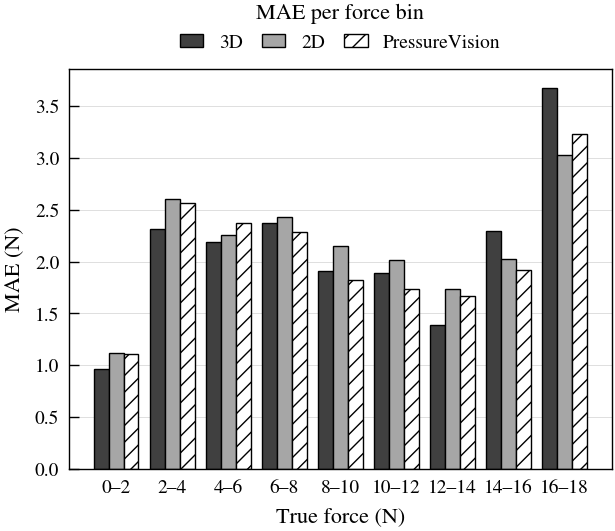

In [114]:
models = list(runs)
PLOT_FORCE_EDGES = np.arange(0, 18 + 1, 2)   # 2 N bins from 0 to 18 N for the plots (the tables use config's force_bins_n)
true_n = common["true_n"].to_numpy()
# [low, high), the last bin [16, 18] - as np.histogram, so the bins match the distribution plot below
plot_bins = [(true_n >= low) & ((true_n < high) | ((high == PLOT_FORCE_EDGES[-1]) & (true_n == high)))
             for low, high in zip(PLOT_FORCE_EDGES[:-1], PLOT_FORCE_EDGES[1:])]
fig, ax = plt.subplots(figsize=(3.5, 2.6))
x = np.arange(len(plot_bins))
width = 0.8 / len(models)
for k, model in enumerate(models):
    abs_err = np.abs(common[f"pred_{model}"].to_numpy() - true_n)
    ax.bar(x + (k - (len(models) - 1) / 2) * width,
           [abs_err[b].mean() if b.any() else np.nan for b in plot_bins], width,
           edgecolor="black", linewidth=0.5, label=model, **BAR_STYLES[k % len(BAR_STYLES)])
no_contact_err = {m: np.abs(common[f"pred_{m}"] - common["true_n"]).to_numpy()[masks["no_contact"]].mean()
                  for m in models}
print("MAE no contact: " + ", ".join(f"{m} {v:.2f} N" for m, v in no_contact_err.items()))
ax.set_xticks(x)
ax.set_xticklabels([f"{low:g}\u2013{high:g}" for low, high in zip(PLOT_FORCE_EDGES[:-1], PLOT_FORCE_EDGES[1:])])
ax.set_xlabel("True force (N)")
ax.set_ylabel("MAE (N)")
ax.set_title("MAE per force bin", pad=18)
ax.set_ylim(bottom=0)
ax.set_axisbelow(True)
ax.yaxis.grid(True, **GRID)
ax.legend(ncol=len(models), loc="lower center", bbox_to_anchor=(0.5, 1.0), frameon=False, handlelength=1.2, columnspacing=1.0)
fig.savefig(os.path.join(out_dir, "force_bin_mae.pdf"))
fig.savefig(os.path.join(out_dir, "force_bin_mae.png"))
plt.show()


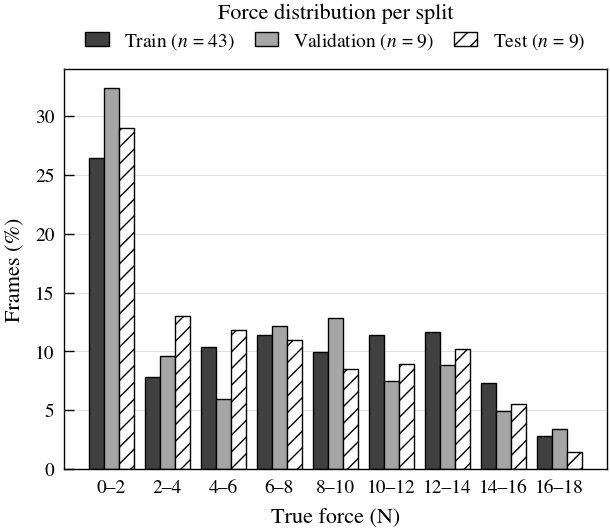

In [115]:
# Label distribution per split over the usable frames (as in the trivial baseline)
split_names = {"train": "Train", "val": "Validation", "test": "Test"}
edges = PLOT_FORCE_EDGES
dist_labels = [f"{low:g}\u2013{high:g}" for low, high in zip(edges[:-1], edges[1:])]
fig, ax = plt.subplots(figsize=(3.5, 2.6))
x = np.arange(len(dist_labels))
width = 0.8 / len(split_names)
for k, (split, name) in enumerate(split_names.items()):
    labels = load_truth(data_root, splits[split])
    force = labels.loc[(labels["artifact"] == 0) & (labels["force_n"] <= settings["max_label_force_n"]), "force_n"].to_numpy()
    counts = np.histogram(force, bins=edges)[0]
    ax.bar(x + (k - (len(split_names) - 1) / 2) * width, np.array(counts) / len(force) * 100, width,
           edgecolor="black", linewidth=0.5, label=f"{name} ($n$ = {len(splits[split])})",
           **BAR_STYLES[k % len(BAR_STYLES)])
ax.set_xticks(x)
ax.set_xticklabels(dist_labels)
ax.set_xlabel("True force (N)")
ax.set_ylabel("Frames (%)")
ax.set_title("Force distribution per split", pad=18)
ax.set_ylim(bottom=0)
ax.set_axisbelow(True)
ax.yaxis.grid(True, **GRID)
ax.legend(ncol=len(split_names), loc="lower center", bbox_to_anchor=(0.5, 1.0), frameon=False, handlelength=1.2, columnspacing=1.0)
fig.savefig(os.path.join(out_dir, "data_distribution.pdf"))
fig.savefig(os.path.join(out_dir, "data_distribution.png"))
plt.show()


## Validation MAE per epoch (IEEE figure)

Validation MAE (N) per epoch for every model, from the `metrics_history.csv` next to its run (seed) with the lowest MAE on the common test frames. Every model keeps the checkpoint of its lowest validation MAE (marked). PressureVision's epoch 0 (zero-shot, no training) is left out. The training MAE is not logged, so only validation is shown.

Formatted for an IEEE single-column figure (style set in the setup cell, as in `plotValidation.ipynb`): 3.5 in wide, Times-style serif at 8 pt, vector PDF, grayscale with the models told apart by line style and marker. Saved as `validation_mae_curves.pdf` / `.png`.


3D: run with the lowest MAE (1.865 N of 1.913, 1.865, 1.871): Model/checkpoints/seed_2/eval_test, 19 epochs
2D: run with the lowest MAE (1.961 N of 2.034, 2.029, 1.961): Model2D/checkpoints/seed_3/eval_test, 21 epochs
PressureVision: run with the lowest MAE (1.845 N of 1.890, 1.893, 1.845): ../ForceEstimationPressureVision/Model/checkpoints/pressurevision_seed_3/eval_test, 54 epochs


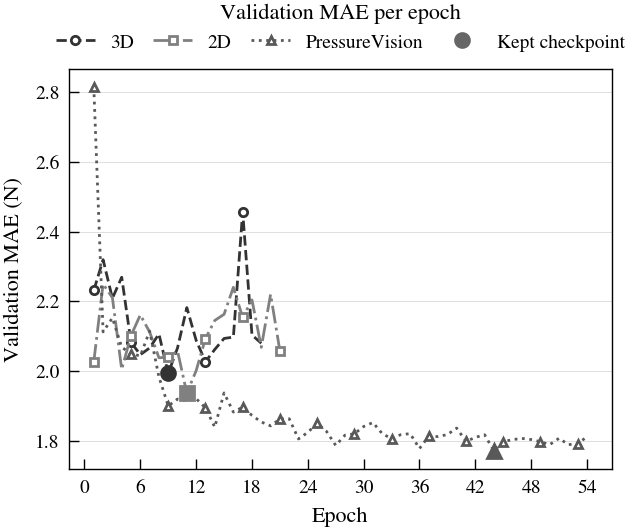

In [116]:
MARKERS = ["o", "s", "^"]

best_histories = {}   # {model: metrics_history of its run with the lowest MAE on the common test frames}
for model, folders in runs.items():
    run_mae = [metrics["mae_n"] for metrics in per_run_metrics[model]]   # same order as folders
    best = int(np.argmin(run_mae))
    history_path = os.path.join(os.path.dirname(folders[best]), "metrics_history.csv")
    if not os.path.isfile(history_path):
        print(f"[compare] WARNING: {history_path} missing - {model} left out of the validation curves")
        continue
    history = pd.read_csv(history_path)
    best_histories[model] = history[history["epoch"] >= 1]
    print(f"{model}: run with the lowest MAE ({run_mae[best]:.3f} N of {', '.join(f'{m:.3f}' for m in run_mae)}): "
          f"{os.path.relpath(folders[best], REPO_ROOT)}, {history['epoch'].max()} epochs")

fig, ax = plt.subplots(figsize=(3.5, 2.6))
for k, (model, h) in enumerate(best_histories.items()):
    style = LINE_STYLES[k % len(LINE_STYLES)]
    ax.plot(h["epoch"], h["val_mae_n"], marker=MARKERS[k % len(MARKERS)], markevery=4,
            markerfacecolor="white", label=model, **style)
    best_epoch = h.loc[h["val_mae_n"].idxmin()]
    ax.plot(best_epoch["epoch"], best_epoch["val_mae_n"], marker=MARKERS[k % len(MARKERS)], markersize=5,
            color=style["color"], linestyle="none", zorder=4)
ax.plot([], [], marker="o", color="0.4", linestyle="none", markersize=5, label="Kept checkpoint")
ax.set_xlabel("Epoch")
ax.set_ylabel("Validation MAE (N)")
ax.set_title("Validation MAE per epoch", pad=18)
ax.xaxis.set_major_locator(plt.MaxNLocator(integer=True))
ax.set_axisbelow(True)
ax.yaxis.grid(True, **GRID)
ax.legend(ncol=len(best_histories) + 1, loc="lower center", bbox_to_anchor=(0.5, 1.0), frameon=False, handlelength=2.0, columnspacing=1.0)
fig.savefig(os.path.join(out_dir, "validation_mae_curves.pdf"))
fig.savefig(os.path.join(out_dir, "validation_mae_curves.png"))
plt.show()


## Predicted vs. true force (IEEE figure)

The scatter plot from `explore.ipynb`, with one panel per model, on the common test frames. Each model's prediction is averaged over its seeds (the `pred_<model>` columns of `common_predictions.csv`). All panels share the same axes. The dashed line is the identity (perfect prediction). The points are rasterized inside the vector PDF to keep the file small. Saved as `scatter_pred_vs_true.pdf` / `.png`.

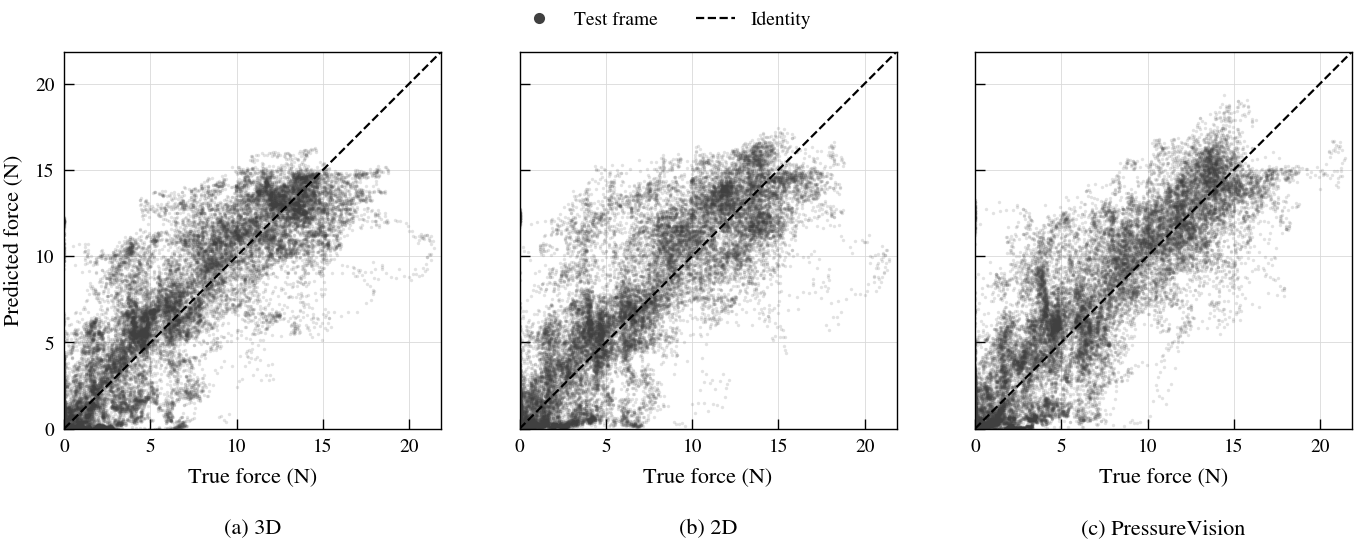

In [117]:
scatter_models = list(runs)
all_values = np.concatenate([common["true_n"].to_numpy()] + [common[f"pred_{m}"].to_numpy() for m in scatter_models])
lims = [min(0.0, all_values.min()), all_values.max() * 1.02]

fig, axes = plt.subplots(1, len(scatter_models), figsize=(7.16, 2.9), squeeze=False, sharex=True, sharey=True)
for panel, (ax, model) in enumerate(zip(axes[0], scatter_models)):
    ax.scatter(common["true_n"], common[f"pred_{model}"], s=1.5, alpha=0.15, color="0.25", linewidths=0,
               rasterized=True, label="Test frame")
    ax.plot(lims, lims, "--", color="black", linewidth=0.8, label="Identity")
    ax.set_xlim(lims)
    ax.set_ylim(lims)
    ax.set_aspect("equal")
    ax.xaxis.set_major_locator(plt.MultipleLocator(5))
    ax.yaxis.set_major_locator(plt.MultipleLocator(5))
    ax.set_xlabel("True force (N)")
    if panel == 0:
        ax.set_ylabel("Predicted force (N)")
    ax.set_axisbelow(True)
    ax.grid(True, **GRID)
    ax.text(0.5, -0.24, f"({chr(ord('a') + panel)}) {model}", transform=ax.transAxes, ha="center", va="top")

handles, labels = axes[0, 0].get_legend_handles_labels()
handles[0] = plt.Line2D([], [], color="0.25", marker="o", linestyle="none", markersize=3)   # opaque legend marker
fig.legend(handles, labels, loc="upper center", ncol=2, frameon=False, bbox_to_anchor=(0.5, 1.0))
fig.subplots_adjust(left=0.07, right=0.99, top=0.9, bottom=0.25, wspace=0.12)
fig.savefig(os.path.join(out_dir, "scatter_pred_vs_true.pdf"))
fig.savefig(os.path.join(out_dir, "scatter_pred_vs_true.png"))
plt.show()


## Inference cost (optional)

Runs only with `RUN_BENCHMARK = True`. Runs `comparison/benchmarkModel.py` once per model in the `benchmark` block (separate processes: the projects' modules share names) and writes `benchmark.json`. Needs no predictions: to only benchmark, run the setup cell, the helper cells and the cells below (`runs` is looked up here if the comparison cells were skipped).

In [118]:
def benchmark_checkpoint(name, model_settings, runs):
    """Checkpoint to benchmark: the benchmark block's explicit `checkpoint`,
    else best_model.pt next to the model's first evaluated run, else
    <code_dir>/checkpoints/best_model.pt. Weights don't change the timing,
    only which architecture/input size gets built.
    """
    candidates = [model_settings.get("checkpoint")]
    if runs.get(name):
        candidates.append(os.path.join(os.path.dirname(runs[name][0]), "best_model.pt"))
    candidates.append(os.path.join(model_settings["code_dir"], "checkpoints", "best_model.pt"))
    for candidate in candidates:
        if candidate and os.path.isfile(repo_path(candidate)):
            return repo_path(candidate)
    return None


def run_benchmarks(benchmark_settings, runs):
    """Runs comparison/benchmarkModel.py once per model in
    benchmark_settings['models']. Returns {model: result dict}; models
    without a checkpoint or whose benchmark fails are reported and left out.
    """
    script = os.path.join(REPO_ROOT, "comparison", "benchmarkModel.py")
    options = {k: v for k, v in benchmark_settings.items() if k != "models"}
    results = {}
    for name, model_settings in benchmark_settings["models"].items():
        checkpoint = benchmark_checkpoint(name, model_settings, runs)
        if checkpoint is None:
            print(f"[compare] WARNING: no checkpoint found to benchmark {name} - left out")
            continue
        print(f"[compare] benchmarking {name} ({model_settings['kind']}) from {checkpoint}")
        with tempfile.TemporaryDirectory() as tmp:
            out_path = os.path.join(tmp, "result.json")
            completed = subprocess.run(
                [sys.executable, script, "--kind", model_settings["kind"], "--code_dir", repo_path(model_settings["code_dir"]),
                 "--checkpoint", checkpoint, "--settings", json.dumps(options), "--out", out_path],
                cwd=repo_path(model_settings["code_dir"]), capture_output=True, text=True)
            print(completed.stdout + completed.stderr, end="")
            if completed.returncode != 0 or not os.path.isfile(out_path):
                print(f"[compare] WARNING: benchmark of {name} failed (exit code {completed.returncode}) - left out")
                continue
            with open(out_path) as f:
                results[name] = json.load(f)
    return results


def benchmark_markdown(results, settings):
    if not results:
        return "No model could be benchmarked."
    models = list(results)
    batch_size = settings["batch_size"]
    first = results[models[0]]
    lines = [f"Device: {first['device']}, precision: {first['precision']}, random inputs of each model's own size, "
             f"{settings['timed_iterations']} timed passes after {settings['warmup_iterations']} warm-up. "
             "Fingertip tracking and cropping are shared by all models and not included.", "",
             "| | " + " | ".join(models) + " |", "|---" * (len(models) + 1) + "|"]

    def row(label, key, fmt):
        return f"| {label} | " + " | ".join(fmt.format(results[m][key]) if key in results[m] else "-"
                                           for m in models) + " |"
    lines += [
        f"| input | " + " | ".join(results[m]["input"] for m in models) + " |",
        row("frames per prediction", "frames_per_prediction", "{}"),
        f"| parameters (M) | " + " | ".join(f"{results[m]['parameters'] / 1e6:.2f}" for m in models) + " |",
        row("checkpoint size (MB)", "checkpoint_mb", "{:.1f}"),
        row("GFLOPs per prediction", "gflops_per_prediction", "{:.2f}"),
        row("GPU latency, batch 1, median (ms)", "latency_ms_median", "{:.2f}"),
        row("GPU latency, batch 1, p95 (ms)", "latency_ms_p95", "{:.2f}"),
        f"| max rate, batch 1 (predictions/s) | " + " | ".join(f"{1000.0 / results[m]['latency_ms_median']:.0f}"
                                                              for m in models) + " |",
        row(f"throughput, batch {batch_size} (predictions/s)", "throughput_predictions_per_s", "{:.0f}"),
        row("peak GPU memory, batch 1 (MB)", "peak_gpu_memory_mb_batch1", "{:.0f}"),
        row(f"peak GPU memory, batch {batch_size} (MB)", f"peak_gpu_memory_mb_batch{batch_size}", "{:.0f}"),
    ]
    if any("cpu_latency_ms_median" in results[m] for m in models):
        lines += [row(f"CPU latency, batch 1, median (ms, {settings['cpu_threads']} threads)", "cpu_latency_ms_median", "{:.1f}"),
                  row("CPU latency, batch 1, p95 (ms)", "cpu_latency_ms_p95", "{:.1f}")]
    frame_budget_ms = 1000.0 / settings["camera_fps"]
    lines += ["", f"Real time at {settings['camera_fps']} fps (one prediction per frame, budget {frame_budget_ms:.1f} ms): " +
              ", ".join(f"{m} {'yes' if results[m]['latency_ms_median'] <= frame_budget_ms else 'no'}" for m in models) +
              " (GPU, batch 1). The 3D model re-processes its whole window for every new frame.", "",
              "GPU latency at batch 1 is largely fixed per-call overhead (Python, kernel launches), so for small models "
              "it says little about compute - compare GFLOPs, batched throughput and CPU latency for that. "
              "Run on the deployment machine for real-time numbers."]
    return "\n".join(lines)

In [119]:
if RUN_BENCHMARK:
    if "runs" not in globals():
        runs = find_runs(settings["models"])
    benchmark_results = run_benchmarks(settings["benchmark"], runs)
    with open(os.path.join(out_dir, "benchmark.json"), "w") as f:
        json.dump(benchmark_results, f, indent=2)
    display(Markdown(benchmark_markdown(benchmark_results, settings["benchmark"])))
else:
    print("RUN_BENCHMARK is False - set it in the first cell to measure inference cost")

RUN_BENCHMARK is False - set it in the first cell to measure inference cost
